Block 2 Checkpoint - Bouncing Balls

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import engine as eng
import world_animate as animate
rng = np.random.default_rng()

The below code utilizes my physics engine to simulate a box of hot gas connected to a box of cold gas by a tube. This simulation showcases how pressure equalizes, with more hot bodies ending up on the cold side than cold bodies on the hot, as the pressure on the hot side is higher. My animation script colors bodies by charge, so charge as been added to the bodies to distinguish them, however charge interactions are not included in this simulation.

In [2]:
# Defining the Geometry of the World
p1, p2, p3, p4, p5, p6    = [(-1,-0.5),(-1,-2.5),(-6,-2.5),(-6,2.5),(-1,2.5),(-1,0.5)]
p7, p8, p9, p10, p11, p12 = [(1,0.5),(1,2.5),(6,2.5),(6,-2.5),(1,-2.5),(1,-0.5)]

walls = [eng.Wall(p1,p2), eng.Wall(p2,p3), eng.Wall(p3,p4), eng.Wall(p4,p5), eng.Wall(p5,p6), eng.Wall(p6,p7),
         eng.Wall(p7,p8), eng.Wall(p8,p9), eng.Wall(p9,p10), eng.Wall(p10,p11), eng.Wall(p11,p12), eng.Wall(p12,p1)]

# Initializing the Bodies of the World
n_hot = 50
n_cold = 50
radius = 0.15

v_hot = np.linspace(-3.5,3.5,100)
v_cold = np.linspace(-0.75,0.75,100)
rx_hot = np.linspace(-6+radius,-1-radius,n_hot)
ry_hot = np.linspace(-2.5+radius,2.5-radius,n_hot)
rx_cold = np.linspace(1+radius,6-radius,n_cold)
ry_cold = np.linspace(-2.5+radius,2.5-radius,n_cold)

bodies = []

rx_hot = rng.permutation(rx_hot)
ry_hot = rng.permutation(ry_hot)

for i in range(n_hot):
    v = (rng.choice(v_hot,size=2,replace=True))
    bodies.append(eng.Body(r=(rx_hot[i],ry_hot[i]),v=v, radius=radius, charge=-1))

rx_cold = rng.permutation(rx_cold)
ry_cold = rng.permutation(ry_cold)

for i in range(n_cold):
    v = (rng.choice(v_cold,size=2,replace=True))
    bodies.append(eng.Body(r=(rx_cold[i],ry_cold[i]),v=v, radius=radius, charge=1))

# Initializing World w/ Spatial Gridding
world = eng.World(integrator=eng.Euler_Cromer(), bodies=bodies, walls=walls, constraints=[eng.Wall_Collisions(), eng.Body_Collisions()],
                  x_ext=(-6.1,6.1), y_ext=(-2.6,2.6), grid_n=40)
animate.animate_world(world, x_ext=(-6.1,6.1), y_ext=(-2.6,2.6), frames=2000, filename="Pressure_Animation.mp4")

The next simulation shows pairs of balls connected by springs bouncing in an irregularly shaped box with charge interactions between them. From the Animation, it is obvious that energy is not remotely conserved in this simulation. The last code block shows that for this simulation, energy conservation is maintained for arbitrarily small values of dt.

In [4]:
# Defining the Geometry of the World
p1, p2, p3, p4, p5, p6, p7, p8, p9 = [(0,4),(2.5,3.5),(1.5,0.5),(3,-2),(1.5,-4),(-1.5,-4),(-3,-2),(-1.5,0.5),(-2.5,3.5)]

walls = [eng.Wall(p1,p2), eng.Wall(p2,p3), eng.Wall(p3,p4), eng.Wall(p4,p5), eng.Wall(p5,p6), eng.Wall(p6,p7),
         eng.Wall(p7,p8), eng.Wall(p8,p9), eng.Wall(p9,p1)]

# Initializing the Bodies and Springs of the World
B1,B2,B3,B4,B5,B6,B7,B8 = [eng.Body(r=(-1.1,-3.3),v=(-2,3.3),radius=0.3,charge=-1), eng.Body(r=(-0.5,-3.3),v=(1.5,-1.3),radius=0.3,charge=-1),
                           eng.Body(r=(1.9,3.2),v=(-2.0,-4.0),radius=0.3,charge=1), eng.Body(r=(0.3,3.5),v=(-0.0,0.0),radius=0.3,charge=1),
                           eng.Body(r=(0.1,0.3),v=(1.1,-2.3),radius=0.3,charge=-1), eng.Body(r=(-0.1,0.9),v=(-2.3,2.1),radius=0.3,charge=1),
                           eng.Body(r=(-2.3,-1.5),v=(3.6,-2.1),radius=0.3,charge=-1), eng.Body(r=(-1.9,-1.8),v=(1.6,-1.1),radius=0.3,charge=1)]

r_0 = 1
k = 5
S1, S2, S3, S4 = [eng.Spring(B1,B2,r_0=r_0,k=k),eng.Spring(B3,B4,r_0=r_0,k=k),eng.Spring(B5,B6,r_0=r_0,k=k),eng.Spring(B7,B8,r_0=r_0,k=k)]

# Initializing World w/ Spatial Gridding
world = eng.World(integrator=eng.Euler_Cromer(), bodies=[B1,B2,B3,B4,B5,B6,B7,B8], walls=walls, 
                  constraints=[eng.Wall_Collisions(), eng.Body_Collisions()],
                  forces=[S1,S2,S3,S4, eng.Coulombic_Interaction(k=7)], x_ext=(-4.1,4.1), y_ext=(-4.1,4.1), grid_n=20)
animate.animate_world(world, x_ext=(-4.1,4.1), y_ext=(-4.1,4.1), frames=2000, filename="Spring_Box.mp4",
                      show={'Time': lambda W: W.t, 'Energy': lambda W: W.total_energy()})

Text(0.5, 1.0, 'Max energy Drift Over 10s vs dt')

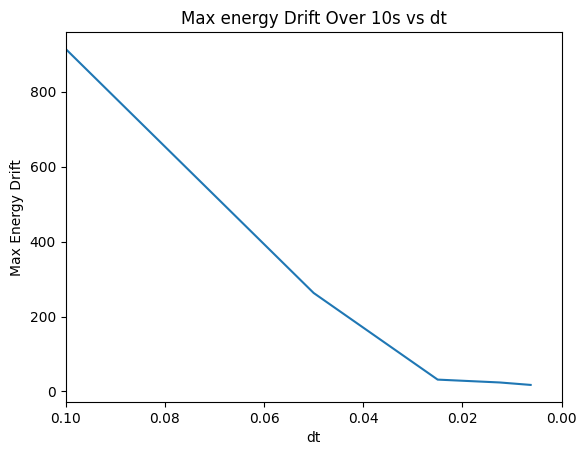

In [3]:
dt_list = []
dE_max = []

for i in range(5):
    dt = 0.1*2**(-i)

    p1, p2, p3, p4, p5, p6, p7, p8, p9 = [(0,4),(2.5,3.5),(1.5,0.5),(3,-2),(1.5,-4),(-1.5,-4),(-3,-2),(-1.5,0.5),(-2.5,3.5)]

    walls = [eng.Wall(p1,p2), eng.Wall(p2,p3), eng.Wall(p3,p4), eng.Wall(p4,p5), eng.Wall(p5,p6), eng.Wall(p6,p7),
            eng.Wall(p7,p8), eng.Wall(p8,p9), eng.Wall(p9,p1)]

    B1,B2,B3,B4,B5,B6,B7,B8 = [eng.Body(r=(-1.1,-3.3),v=(-2,3.3),radius=0.3,charge=-1), eng.Body(r=(-0.5,-3.3),v=(1.5,-1.3),radius=0.3,charge=-1),
                            eng.Body(r=(1.9,3.2),v=(-2.0,-4.0),radius=0.3,charge=1), eng.Body(r=(0.3,3.5),v=(-0.0,0.0),radius=0.3,charge=1),
                            eng.Body(r=(0.1,0.3),v=(1.1,-2.3),radius=0.3,charge=-1), eng.Body(r=(-0.1,0.9),v=(-2.3,2.1),radius=0.3,charge=1),
                            eng.Body(r=(-2.3,-1.5),v=(3.6,-2.1),radius=0.3,charge=-1), eng.Body(r=(-1.9,-1.8),v=(1.6,-1.1),radius=0.3,charge=1)]

    r_0 = 1
    k = 5
    S1, S2, S3, S4 = [eng.Spring(B1,B2,r_0=r_0,k=k),eng.Spring(B3,B4,r_0=r_0,k=k),eng.Spring(B5,B6,r_0=r_0,k=k),eng.Spring(B7,B8,r_0=r_0,k=k)]

    world = eng.World(integrator=eng.Euler_Cromer(), bodies=[B1,B2,B3,B4,B5,B6,B7,B8], walls=walls, 
                    constraints=[eng.Wall_Collisions(), eng.Body_Collisions()],
                    forces=[S1,S2,S3,S4, eng.Coulombic_Interaction(k=7)], x_ext=(-4.1,4.1), y_ext=(-4.1,4.1), grid_n=20)
    world.record('E', lambda W: W.total_energy())

    world.run(dt,end_t=10)
    dt_list.append(dt)
    dE_max.append(max([abs(world.history['E'][0] - E) for E in world.history['E']]))

plt.plot(dt_list,dE_max)
plt.xlim((0.1,0))
plt.xlabel('dt')
plt.ylabel('Max Energy Drift')
plt.title('Max energy Drift Over 10s vs dt')
